I need to select about 12 samples (6 for each condition) for Astral and timsTOF.

In this notebook, this is chosen

## Selection strategy

The QC wells in `adata_precursor_qc` are two-proteome mixes at two mixing ratios
(`source name` == `QC - HYE A` / `QC - HYE B`), each injected ~11 times per lab. Several
labs contributed Astral runs (DTU, IMP, KI, LSMBO, Wyss) and several contributed timsTOF
runs (BYU, Broad, IMP).

**Labs:** LSMBO for Astral, IMP for timsTOF, set directly (`SELECTED_PLATES` below). An
automated ranking by multi-engine quantification accuracy is still shown further down for
context, but it is not what drives the final choice.

**Replicates within each lab (6 per condition):** to avoid ranking replicates by any single
search engine's idiosyncrasies, both criteria below reuse the multi-engine ProteoBench
results already computed for this dataset (six independent search engines: DIA-NN,
Spectronaut, PEAKS, CHIMERYS, AlphaDIA, MSFragger/FragPipe), excluding MBR and
TIC-normalized settings throughout:

1. **Identification depth** — median non-missing precursor count per raw file, across
   engines.
2. **Overlap with peers (Jaccard)** — a replicate that is deep but identifies a mostly
   different set of precursors than its same-condition peers is not obviously a "good"
   replicate for a quantification benchmark; it may be picking up run-specific noise rather
   than the shared HYE signal. For each pair of same-condition replicates, the Jaccard
   index of their identified-precursor sets is computed per engine and the median is taken
   across engines. Each replicate's average similarity to its peers is then used alongside
   identification depth.

The two criteria are combined via rank-averaging (see "Step 3") rather than picking on
depth alone.

In [34]:
import os
from tqdm import tqdm
import numpy as np
import pandas as pd
from pathlib import Path
import anndata

tqdm.pandas()

In [35]:
NOTEBOOK_DIR = Path().resolve()
ROOT_OUT      = NOTEBOOK_DIR / "../../Data"
ROOT_OUT      = ROOT_OUT.resolve()
ROOT_OUT.mkdir(parents=True, exist_ok=True)

# Allow user override via environment variable
ROOT_OUT = Path(os.environ.get("SCI_DATA_DIR", ROOT_OUT))

ROOT_OUT.mkdir(parents=True, exist_ok=True)
print(f"Output directory: {ROOT_OUT}")



#########################
### CHANGE PATHS HERE ###
#########################
# 1. Figure storage
### DIANN
# FIGURES_OUT = NOTEBOOK_DIR / "../../Figures/0_DIANN/v2.6"

### Spectronaut
FIGURES_OUT = NOTEBOOK_DIR / "../../Figures/1_Spectronaut"


# 2. Loading AnnData
# Change if paths don't match.
# Or change the path after AnnData to specify search result of given search tool.
### DIANN
# ANNDATA_IN = os.path.join(
#     ROOT_OUT,
#     'AnnData',
#     'DIANN',
#     'v2.6',
#     'second_pass'
# )
# Spectronaut
ROOT_IN = "/public/conode53/sam/SCI_paper/Zenodo/Data"
ANNDATA_IN = os.path.join(
    ROOT_IN,
    "AnnData",
    'Spectronaut'
)

FIGURES_OUT = FIGURES_OUT.resolve()
FIGURES_OUT.mkdir(parents=True, exist_ok=True)

# Overwrite with environment variable
FIGURES_OUT = Path(os.environ.get("SCI_FIGURES_DIR", FIGURES_OUT))
print(f"Figures directory: {FIGURES_OUT}")



Output directory: /home/sam/SCI/SCI/Notebooks/Data
Figures directory: /home/sam/SCI/SCI/Notebooks/Figures/1_Spectronaut


In [36]:
adata_precursor_qc = anndata.io.read_h5ad(
    os.path.join(ANNDATA_IN,
                #  'base',
                 'adata_precursor_qc.h5ad')
)
adata_protein_qc = anndata.io.read_h5ad(
    os.path.join(ANNDATA_IN,
                #  'base',
                 'adata_protein_qc.h5ad')
)

In [37]:
adata_precursor_qc

AnnData object with n_obs × n_vars = 196 × 37789
    obs: 'sample_name', 'plate_id', 'plate_idx', 'source name', 'comment[X position]', 'comment[Y position]', 'comment[Plate Number]', 'comment[Gradient time]', 'comment[thawing timepoint]', 'comment[plate arrival]', 'injection_order', 'institute_name', 'Reinjection', 'Diameter', 'Elongation', 'Circularity', 'Doublet', 'Dividing', 'Dying', 'CellInBlank', 'comment[plate arrival]_date', 'comment[plate arrival]_time', 'comment[plate arrival]_datetime', 'comment[Gradient time]_date', 'comment[Gradient time]_time', 'comment[Gradient time]_datetime', 'instrument_type', 'n_precursors'
    var: 'PG.ProteinGroups', 'PG.ProteinAccessions', 'PEP.StrippedSequence', 'PEP.IsProteotypic', 'EG.ModifiedSequence', 'FG.Charge', 'FG.LabeledSequence', 'PG.Pvalue', 'PG.Qvalue', 'FG.Qvalue', 'EG.GlobalPrecursorQvalue', 'PG.Cscore', 'EG.ApexRT', 'EG.RTPredicted', 'EG.iRTEmpirical', 'EG.iRTPredicted', 'FG.PrecWindowNumber', 'FG.CScore', 'Contaminant'
    layers:

<Axes: xlabel='n_precursors', ylabel='plate_idx'>

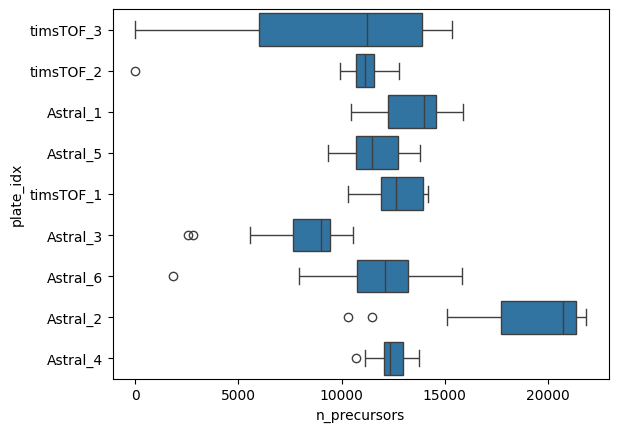

In [38]:
import seaborn as sns
sns.boxplot(
    adata_precursor_qc.obs,
    x='n_precursors',
    y='plate_idx'
)

In [39]:
adata_precursor_qc.obs[adata_precursor_qc.obs.plate_idx=='timsTOF_1']

,sample_name,plate_id,plate_idx,source name,comment[X position],comment[Y position],comment[Plate Number],comment[Gradient time],comment[thawing timepoint],comment[plate arrival],...,Dying,CellInBlank,comment[plate arrival]_date,comment[plate arrival]_time,comment[plate arrival]_datetime,comment[Gradient time]_date,comment[Gradient time]_time,comment[Gradient time]_datetime,instrument_type,n_precursors
sample_id,,,,,,,,,,,,,,,,,,,,,
hyea_qc_b13|IMP_timsTOF_1,hyea_qc_b13,IMP_timsTOF_1,timsTOF_1,QC - HYE A,2,13,6,20251018-163404,20251016-134600,20251007-132900,...,False,False,2025-10-07,13.483333,2025-10-07 13:29:00,2025-10-18,16.567778,2025-10-18 16:34:04,timsTOF,12551
hyea_qc_b14|IMP_timsTOF_1,hyea_qc_b14,IMP_timsTOF_1,timsTOF_1,QC - HYE A,2,14,6,20251018-113009,20251016-134600,20251007-132900,...,False,False,2025-10-07,13.483333,2025-10-07 13:29:00,2025-10-18,11.502500,2025-10-18 11:30:09,timsTOF,11792
hyea_qc_b15|IMP_timsTOF_1,hyea_qc_b15,IMP_timsTOF_1,timsTOF_1,QC - HYE A,2,15,6,20251018-123644,20251016-134600,20251007-132900,...,False,False,2025-10-07,13.483333,2025-10-07 13:29:00,2025-10-18,12.612222,2025-10-18 12:36:44,timsTOF,11644
hyea_qc_b16|IMP_timsTOF_1,hyea_qc_b16,IMP_timsTOF_1,timsTOF_1,QC - HYE A,2,16,6,20251016-214323,20251016-134600,20251007-132900,...,False,False,2025-10-07,13.483333,2025-10-07 13:29:00,2025-10-16,21.723056,2025-10-16 21:43:23,timsTOF,10319
hyea_qc_b17|IMP_timsTOF_1,hyea_qc_b17,IMP_timsTOF_1,timsTOF_1,QC - HYE A,2,17,6,20251018-114914,20251016-134600,20251007-132900,...,False,False,2025-10-07,13.483333,2025-10-07 13:29:00,2025-10-18,11.820556,2025-10-18 11:49:14,timsTOF,12445
hyea_qc_b18|IMP_timsTOF_1,hyea_qc_b18,IMP_timsTOF_1,timsTOF_1,QC - HYE A,2,18,6,20251017-194951,20251016-134600,20251007-132900,...,False,False,2025-10-07,13.483333,2025-10-07 13:29:00,2025-10-17,19.830833,2025-10-17 19:49:51,timsTOF,12121
hyea_qc_b19|IMP_timsTOF_1,hyea_qc_b19,IMP_timsTOF_1,timsTOF_1,QC - HYE A,2,19,6,20251017-212501,20251016-134600,20251007-132900,...,False,False,2025-10-07,13.483333,2025-10-07 13:29:00,2025-10-17,21.416944,2025-10-17 21:25:01,timsTOF,11867
hyea_qc_b20|IMP_timsTOF_1,hyea_qc_b20,IMP_timsTOF_1,timsTOF_1,QC - HYE A,2,20,6,20251017-201818,20251016-134600,20251007-132900,...,False,False,2025-10-07,13.483333,2025-10-07 13:29:00,2025-10-17,20.305000,2025-10-17 20:18:18,timsTOF,12115
hyea_qc_b21|IMP_timsTOF_1,hyea_qc_b21,IMP_timsTOF_1,timsTOF_1,QC - HYE A,2,21,6,20251019-090150,20251016-134600,20251007-132900,...,False,False,2025-10-07,13.483333,2025-10-07 13:29:00,2025-10-19,9.030556,2025-10-19 09:01:50,timsTOF,11704


## Chosen labs

Set directly rather than derived from the automated ranking further down.

In [40]:
import glob

PROTEOBENCH_DIR = Path('/home/sam/SCI/SCI/Data/ProteoBench2')

SELECTED_PLATES = {"Astral": "LSMBO_Astral_1", "timsTOF": "IMP_timsTOF_1"}
SELECTED_PLATES

{'Astral': 'LSMBO_Astral_1', 'timsTOF': 'IMP_timsTOF_1'}

### Step 0 — load per-engine intermediates for the two chosen plates

One dict per instrument: `{"engine [settings]": (intermediate_df, sample_columns)}`,
restricted to non-MBR, non-TIC-normalized settings. Loaded once here and reused below for
both the identification-depth ranking and the Jaccard overlap.

In [41]:
def load_engine_intermediates(plate_id):
    """Load every non-MBR, non-TIC-normalized engine setting cached for this plate.
    Returns {"engine [comments]": (intermediate_df, sample_cols)}."""
    cache_files = glob.glob(str(PROTEOBENCH_DIR / "cache" / f"{plate_id}__*__main.pkl"))
    tables = {}
    for f in cache_files:
        cached = pd.read_pickle(f)
        dp_row = cached["datapoint"].iloc[0]
        if "MBR" in dp_row["comments"] or "TIC-norm" in dp_row["comments"]:
            continue
        intermediate = cached["intermediates"][0]
        sample_cols = [
            c for c in intermediate.columns
            if c.upper().startswith("HYEA_QC") or c.upper().startswith("HYEB_QC")
        ]
        label = f"{dp_row['search_engine']} [{dp_row['comments']}]"
        tables[label] = (intermediate, sample_cols)
    return tables


engine_tables = {
    instrument: load_engine_intermediates(plate_id)
    for instrument, plate_id in SELECTED_PLATES.items()
}
{instrument: list(tables.keys()) for instrument, tables in engine_tables.items()}

{'Astral': ['Spectronaut [DirectDIA+ method-evaluation]',
  'AlphaDIA [Default]',
  'CHIMERYS [5.0.0 MS2(Area)]',
  'MSFragger [standard]',
  'DIA-NN [DIANN 2.6]'],
 'timsTOF': ['AlphaDIA [Default]',
  'CHIMERYS [5.0.0 MS2(Area)]',
  'Spectronaut [DirectDIA+ method-evaluation]',
  'MSFragger [standard]',
  'DIA-NN [DIANN 2.6]']}

### Step 0b — pairwise identification overlap (Jaccard) between replicates

For every engine setting, a raw file's identified-precursor set is the set of precursor
ions with a non-missing intensity in that column. The Jaccard index of these sets is
computed for every pair of raw files, per engine setting, then the median is taken
elementwise across engine settings — a consensus overlap matrix that isn't dominated by
any single engine's behaviour.

<Axes: >

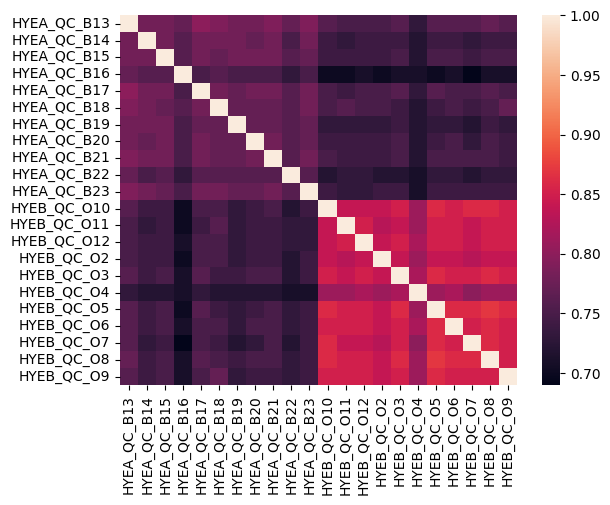

In [55]:
def pairwise_jaccard_matrix(tables):
    """Median (across engine settings) pairwise Jaccard similarity of identified-precursor
    sets between raw files."""
    raw_files = sorted(set.union(*(set(cols) for _, cols in tables.values())))
    engine_matrices = []
    for df, cols in tables.values():
        id_sets = {c: set(df.loc[df[c].notna(), "precursor ion"]) for c in cols}
        mat = np.full((len(raw_files), len(raw_files)), np.nan)
        for i, a in enumerate(raw_files):
            sa = id_sets.get(a, set())
            for j, b in enumerate(raw_files):
                sb = id_sets.get(b, set())
                union = sa | sb
                mat[i, j] = len(sa & sb) / len(union) if union else np.nan
        engine_matrices.append(mat)
    median_mat = np.nanmedian(np.stack(engine_matrices), axis=0)
    return pd.DataFrame(median_mat, index=raw_files, columns=raw_files)


jaccard_matrices = {
    instrument: pairwise_jaccard_matrix(tables)
    for instrument, tables in engine_tables.items()
}
sns.heatmap(jaccard_matrices["timsTOF"].round(2), annot=False)

In [56]:
adata_precursor_qc.obs.loc[
    adata_precursor_qc.obs['plate_idx']=='timsTOF_1',
    ['sample_name', 'comment[X position]', 'comment[Y position]', 'n_precursors']
]

,sample_name,comment[X position],comment[Y position],n_precursors
sample_id,,,,
hyea_qc_b13|IMP_timsTOF_1,hyea_qc_b13,2,13,12551
hyea_qc_b14|IMP_timsTOF_1,hyea_qc_b14,2,14,11792
hyea_qc_b15|IMP_timsTOF_1,hyea_qc_b15,2,15,11644
hyea_qc_b16|IMP_timsTOF_1,hyea_qc_b16,2,16,10319
hyea_qc_b17|IMP_timsTOF_1,hyea_qc_b17,2,17,12445
hyea_qc_b18|IMP_timsTOF_1,hyea_qc_b18,2,18,12121
hyea_qc_b19|IMP_timsTOF_1,hyea_qc_b19,2,19,11867
hyea_qc_b20|IMP_timsTOF_1,hyea_qc_b20,2,20,12115
hyea_qc_b21|IMP_timsTOF_1,hyea_qc_b21,2,21,11704


In [58]:
def avg_peer_similarity(jaccard_matrix):
    """Mean Jaccard similarity of each replicate to the other replicates of the same
    condition (HYE A or HYE B) — a per-replicate consistency-with-peers score."""
    scores = {}
    for prefix in ["HYEA_QC", "HYEB_QC"]:
        cols = [c for c in jaccard_matrix.columns if c.upper().startswith(prefix)]
        sub = jaccard_matrix.loc[cols, cols]
        for c in cols:
            scores[c] = sub.loc[c].drop(index=c).mean()
    return pd.Series(scores, name="avg_peer_jaccard")


peer_similarity = {
    instrument: avg_peer_similarity(matrix)
    for instrument, matrix in jaccard_matrices.items()
}
peer_similarity["timsTOF"].sort_values(ascending=False)

HYEB_QC_O5     0.851829
HYEB_QC_O8     0.850121
HYEB_QC_O6     0.848256
HYEB_QC_O9     0.846948
HYEB_QC_O3     0.845808
HYEB_QC_O10    0.844995
HYEB_QC_O12    0.843913
HYEB_QC_O7     0.843122
HYEB_QC_O11    0.842304
HYEB_QC_O2     0.835280
HYEB_QC_O4     0.813206
HYEA_QC_B13    0.781830
HYEA_QC_B17    0.776121
HYEA_QC_B21    0.774077
HYEA_QC_B15    0.773710
HYEA_QC_B23    0.773635
HYEA_QC_B14    0.772832
HYEA_QC_B18    0.771981
HYEA_QC_B20    0.771872
HYEA_QC_B19    0.770706
HYEA_QC_B22    0.756329
HYEA_QC_B16    0.752910
Name: avg_peer_jaccard, dtype: float64

### Step 1 (reference only) — automated lab comparison by quantification accuracy

Shown for context/sanity-check, not used to make the final choice: for each plate
(lab x instrument), the median `mean_abs_epsilon` across all non-MBR, non-TIC-normalized
engine settings. `SELECTED_PLATES` above (LSMBO for Astral, IMP for timsTOF) was set
directly and overrides whatever this ranking suggests.

In [44]:
datapoints = pd.read_pickle(PROTEOBENCH_DIR / 'datapoints.pkl')

# Exclude MBR and TIC-normalized variants: these are alternative settings per engine,
# not independent quality evidence, and would bias the median toward engines with more
# of them tested.
non_mbr = datapoints[
    ~datapoints["comments"].str.contains("MBR", case=False, na=False)
    & ~datapoints["comments"].str.contains("TIC-norm", case=False, na=False)
].copy()
non_mbr["instrument_type"] = non_mbr["plate_id"].apply(
    lambda x: "Astral" if "Astral" in x else "timsTOF"
)

lab_summary = (
    non_mbr.groupby(["instrument_type", "plate_id"])
    .agg(
        n_engines=("search_engine", "nunique"),
        median_nr_prec=("nr_prec", "median"),
        median_mean_abs_epsilon=("mean_abs_epsilon", "median"),
    )
    .reset_index()
    .sort_values(["instrument_type", "median_mean_abs_epsilon"])
)
lab_summary

,instrument_type,plate_id,n_engines,median_nr_prec,median_mean_abs_epsilon
5,Astral,Wyss_Astral_1,5,9700.0,0.270409
2,Astral,KI_Astral_1,5,8431.5,0.304323
1,Astral,IMP_Astral_1,5,9334.5,0.312034
4,Astral,LSMBO_Astral_1,5,15718.0,0.319177
3,Astral,KI_Astral_2,2,10016.0,0.362444
0,Astral,DTU_Astral_1,5,9963.5,0.379181
8,timsTOF,IMP_timsTOF_1,5,8043.5,0.287504
7,timsTOF,Broad_timsTOF_1,5,8330.0,0.365659
6,timsTOF,BYU_timsTOF_1,5,6003.5,0.41216


In [12]:
# Only compare plates that were benchmarked with the full set of engines, so a plate
# doesn't win just because it happened to be tested against an easier subset.
max_engines = lab_summary.groupby("instrument_type")["n_engines"].transform("max")
fully_benchmarked = lab_summary[lab_summary["n_engines"] == max_engines]

best_plate_per_instrument = (
    fully_benchmarked.sort_values("median_mean_abs_epsilon")
    .groupby("instrument_type")
    .first()["plate_id"]
    .to_dict()
)
best_plate_per_instrument

{'Astral': 'Wyss_Astral_1', 'timsTOF': 'IMP_timsTOF_1'}

This automated ranking would pick Wyss (Astral); `SELECTED_PLATES` above overrides it with
LSMBO for Astral (IMP for timsTOF matches either way).

### Step 2 — rank replicates within each chosen lab by multi-engine consensus depth

Reuses `engine_tables` loaded in Step 0: for each raw file, the median non-missing
precursor count across engine settings. This avoids ranking replicates by any single
engine's behaviour on them.

In [13]:
def per_replicate_consensus_depth(tables):
    """Median non-missing precursor count per raw file, across engine settings."""
    per_engine_counts = {
        label: df[cols].notna().sum() for label, (df, cols) in tables.items()
    }
    counts = pd.DataFrame(per_engine_counts)
    return counts.median(axis=1).rename("median_id_depth").sort_values(ascending=False)


replicate_depth = {
    instrument: per_replicate_consensus_depth(tables)
    for instrument, tables in engine_tables.items()
}
replicate_depth["Astral"]

HYEB_QC_O9     15772.0
HYEB_QC_O6     15045.0
HYEA_QC_B19    14937.5
HYEB_QC_O11    14814.0
HYEB_QC_O5     14672.0
HYEB_QC_O2     14649.0
HYEB_QC_O8     14631.0
HYEB_QC_O7     14534.0
HYEA_QC_B20    14526.0
HYEB_QC_O10    14450.0
HYEA_QC_B17    14410.0
HYEA_QC_B15    14389.0
HYEA_QC_B18    14337.0
HYEA_QC_B14    14216.0
HYEB_QC_O3     14187.0
HYEA_QC_B13    14168.0
HYEB_QC_O12    13486.0
HYEA_QC_B21    13002.0
HYEA_QC_B23    12592.0
HYEA_QC_B22    11688.0
HYEB_QC_O4     11577.0
HYEA_QC_B16     9769.0
Name: median_id_depth, dtype: float64

### Step 3 — combine depth and peer overlap into a final ranking

Neither criterion is used alone: within each condition, a replicate's rank is the average
of its identification-depth rank and its peer-Jaccard-similarity rank. The 6 replicates
with the best (lowest) combined rank per condition are kept.

In [14]:
def composite_ranking(depth, similarity, prefix):
    d = depth[depth.index.str.upper().str.startswith(prefix)]
    s = similarity[similarity.index.str.upper().str.startswith(prefix)]
    ranking = pd.DataFrame({
        "median_id_depth": d,
        "avg_peer_jaccard": s,
        "rank_depth": d.rank(ascending=False),
        "rank_similarity": s.rank(ascending=False),
    })
    ranking["composite_rank"] = (ranking["rank_depth"] + ranking["rank_similarity"]) / 2
    return ranking.sort_values("composite_rank")


composite_ranking(replicate_depth["Astral"], peer_similarity["Astral"], "HYEA_QC")

,median_id_depth,avg_peer_jaccard,rank_depth,rank_similarity,composite_rank
HYEA_QC_B15,14389.0,0.779709,4.0,1.0,2.5
HYEA_QC_B20,14526.0,0.769090,2.0,6.0,4.0
HYEA_QC_B18,14337.0,0.777810,5.0,3.0,4.0
HYEA_QC_B17,14410.0,0.775254,3.0,5.0,4.0
HYEA_QC_B13,14168.0,0.778008,7.0,2.0,4.5
HYEA_QC_B14,14216.0,0.776453,6.0,4.0,5.0
HYEA_QC_B19,14937.5,0.696764,1.0,9.0,5.0
HYEA_QC_B21,13002.0,0.736517,8.0,7.0,7.5
HYEA_QC_B23,12592.0,0.717989,9.0,8.0,8.5
HYEA_QC_B22,11688.0,0.692532,10.0,10.0,10.0


In [15]:
N_PER_CONDITION = 6

selected_rows = []
for instrument, plate_id in SELECTED_PLATES.items():
    depth = replicate_depth[instrument]
    similarity = peer_similarity[instrument]
    for condition, prefix in [("A", "HYEA_QC"), ("B", "HYEB_QC")]:
        ranking = composite_ranking(depth, similarity, prefix)
        top6 = ranking.head(N_PER_CONDITION)
        for rank, (raw_file, row) in enumerate(top6.iterrows(), start=1):
            sample_name = raw_file.lower()
            selected_rows.append({
                "instrument_type": instrument,
                "plate_id": plate_id,
                "condition": condition,
                "sample_name": sample_name,
                "sample_id": f"{sample_name}|{plate_id}",
                "median_id_depth": row["median_id_depth"],
                "avg_peer_jaccard": row["avg_peer_jaccard"],
                "composite_rank": row["composite_rank"],
                "rank_within_condition": rank,
            })

selected_samples = pd.DataFrame(selected_rows)
assert len(selected_samples) == 2 * len(SELECTED_PLATES) * N_PER_CONDITION
assert selected_samples["sample_id"].isin(adata_precursor_qc.obs_names).all()
selected_samples

,instrument_type,plate_id,condition,sample_name,sample_id,median_id_depth,avg_peer_jaccard,composite_rank,rank_within_condition
0,Astral,LSMBO_Astral_1,A,hyea_qc_b15,hyea_qc_b15|LSMBO_Astral_1,14389.0,0.779709,2.5,1
1,Astral,LSMBO_Astral_1,A,hyea_qc_b20,hyea_qc_b20|LSMBO_Astral_1,14526.0,0.769090,4.0,2
2,Astral,LSMBO_Astral_1,A,hyea_qc_b18,hyea_qc_b18|LSMBO_Astral_1,14337.0,0.777810,4.0,3
3,Astral,LSMBO_Astral_1,A,hyea_qc_b17,hyea_qc_b17|LSMBO_Astral_1,14410.0,0.775254,4.0,4
4,Astral,LSMBO_Astral_1,A,hyea_qc_b13,hyea_qc_b13|LSMBO_Astral_1,14168.0,0.778008,4.5,5
5,Astral,LSMBO_Astral_1,A,hyea_qc_b14,hyea_qc_b14|LSMBO_Astral_1,14216.0,0.776453,5.0,6
6,Astral,LSMBO_Astral_1,B,hyeb_qc_o5,hyeb_qc_o5|LSMBO_Astral_1,14672.0,0.805011,3.0,1
7,Astral,LSMBO_Astral_1,B,hyeb_qc_o11,hyeb_qc_o11|LSMBO_Astral_1,14814.0,0.804774,3.5,2
8,Astral,LSMBO_Astral_1,B,hyeb_qc_o8,hyeb_qc_o8|LSMBO_Astral_1,14631.0,0.807284,3.5,3
9,Astral,LSMBO_Astral_1,B,hyeb_qc_o6,hyeb_qc_o6|LSMBO_Astral_1,15045.0,0.801760,4.0,4


In [16]:
OUT_PATH = NOTEBOOK_DIR / "selected_samples.csv"
selected_samples.to_csv(OUT_PATH, index=False)
print(f"Saved {len(selected_samples)} selected samples to {OUT_PATH}")

Saved 24 selected samples to /home/sam/SCI/SCI/Notebooks/6_ProteoBench_modules/QuantModule/selected_samples.csv
